# 05. Feature matching / Сопоставление особенностей

**RU.** Реальные пары фотографий Oxford Affine Covariant Features. Наблюдение — пара кадров одной сцены; признаки — координаты ключевых точек и SIFT/ORB-дескрипторы; целевая разметка — гомография H1→j. `graf` и `leuven` служат для демонстрации и настройки. `wall` и `bikes` остаются для итоговой проверки после фиксации параметров. Кадры одной сцены нельзя случайно распределять между настройкой и тестом. Это учебное разбиение четырёх сцен, не официальный benchmark и не оценка всей популяции сцен.

**EN.** Real photograph pairs from Oxford Affine Covariant Features. An observation is a pair of views of one scene. Features are keypoint coordinates and SIFT/ORB descriptors. The reference target is the H1→j homography. Use `graf` and `leuven` for demonstrations and tuning. Reserve `wall` and `bikes` for evaluation after freezing settings. Never randomly split frames of the same scene across tuning and evaluation. This four-scene teaching split is not the official benchmark or an estimate over all scenes.

**Источники / Sources:** [Oxford dataset](https://www.robots.ox.ac.uk/~vgg/research/affine/), [Data description](https://www.robots.ox.ac.uk/~vgg/research/affine/det_eval_files/DataREADME), Mikolajczyk et al., IJCV 2005; [OpenCV matching](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html).

**Условия / Terms.** Данные доступны на странице авторов для оценки методов; отдельная открытая лицензия на фотографии там не указана. Сохраняйте ссылки и авторство, не приписывайте фотографиям MIT-лицензию кода. Ноутбук загружает оригиналы с Oxford, полноразмерные изображения в репозиторий не включены; в этом разборе сохранены уменьшенные иллюстрации с указанием источника. / The authors provide data for method evaluation; the page does not state a separate open image license. Retain attribution and sources. Do not apply a code MIT license to photographs. The notebook downloads original data from Oxford; full-resolution originals are not bundled; this worked example includes reduced figure previews with attribution.

**Ограничения / Limits.** Плоские сцены или фиксированный центр камеры. Гомография не моделирует произвольный параллакс. Эталонные H имеют погрешность. / Planar scenes or a fixed camera centre. A homography does not model arbitrary parallax. Reference homographies have uncertainty.

**Среда / Environment.** Python 3.11+, CPU, NumPy 2.2.6, OpenCV 4.12.0.88. Четыре архива около 33 MB. SHA-256 проверяется, синтетического fallback нет. / Four archives total about 33 MB. Downloads are checked with SHA-256. There is no synthetic fallback.


## Разбор с решениями / Worked solutions
RU: выполните все ячейки сверху вниз. Ниже приведены решения четырёх заданий и пояснения. Конфигурация выбирается только по validation; анализ test не меняет её.
EN: run all cells in order. The four worked solutions and explanations follow below. Select settings using validation only; test analysis never changes them.

In [1]:
# Colab: run once if necessary, then restart the runtime if requested.
# Colab: при необходимости выполните и перезапустите среду.
# %pip install -q numpy==2.2.6 opencv-python-headless==4.12.0.88 matplotlib


In [2]:
DATA_MANIFEST = {'graf': {'url': 'https://www.robots.ox.ac.uk/~vgg/research/affine/det_eval_files/graf.tar.gz', 'sha256': '999871b945ee968a00a0d5f9af957d1382fb9dae1511cdee9553366817b53b5b', 'bytes': 8414417}, 'leuven': {'url': 'https://www.robots.ox.ac.uk/~vgg/research/affine/det_eval_files/leuven.tar.gz', 'sha256': '9b1ade6e64e5b27eee43463ff8f9ad2bd2f9c6911666e93de2634f3a5c0fe5dc', 'bytes': 6739237}, 'wall': {'url': 'https://www.robots.ox.ac.uk/~vgg/research/affine/det_eval_files/wall.tar.gz', 'sha256': '3cb3df75f40471f093adf6647d13df6a9f4312f7a222fc591d03f6c08e086344', 'bytes': 9991441}, 'bikes': {'url': 'https://www.robots.ox.ac.uk/~vgg/research/affine/det_eval_files/bikes.tar.gz', 'sha256': '3b95c49accadfd71e63c2fa0f7602abcbadd87d7f53ff54eb1efb15210d19e0c', 'bytes': 7366360}}
from pathlib import Path
import hashlib, io, json, tarfile, urllib.request
import numpy as np
import cv2
cv2.setNumThreads(1)
cv2.setRNGSeed(5102026)
DATA = Path('data')
MANIFEST = DATA_MANIFEST

def load_sequence(name):
    spec=MANIFEST[name]; archive=DATA/(name+'.tar.gz'); folder=DATA/name
    DATA.mkdir(exist_ok=True)
    if not archive.exists():
        with urllib.request.urlopen(spec['url'],timeout=120) as response: blob=response.read()
        if hashlib.sha256(blob).hexdigest()!=spec['sha256']: raise RuntimeError('Dataset checksum mismatch')
        archive.write_bytes(blob)
    if hashlib.sha256(archive.read_bytes()).hexdigest()!=spec['sha256']: raise RuntimeError('Dataset checksum mismatch')
    folder.mkdir(exist_ok=True)
    with tarfile.open(archive) as tar:
        for member in tar.getmembers():
            if not member.isfile(): continue
            # Only known flat dataset assets, never arbitrary archive paths.
            leaf=Path(member.name).name
            if leaf not in {*(f'img{i}.ppm' for i in range(1,7)),*(f'H1to{i}p' for i in range(2,7))}:continue
            target=folder/leaf
            if not target.exists():target.write_bytes(tar.extractfile(member).read())
    return folder

def pair(sequence, index=2):
    folder=load_sequence(sequence)
    a=cv2.imread(str(folder/'img1.ppm'),cv2.IMREAD_GRAYSCALE)
    b=cv2.imread(str(folder/f'img{index}.ppm'),cv2.IMREAD_GRAYSCALE)
    if a is None or b is None:raise RuntimeError('Real dataset images unavailable')
    H=np.loadtxt(folder/f'H1to{index}p')
    # Official Oxford repeatability.m specifies coordinates 0..width.
    # Use H1toj directly with OpenCV coordinates; do not add a 1-pixel shift.
    return a,b,H/H[2,2]

def features(image,method='SIFT'):
    detector=cv2.SIFT_create(nfeatures=1500) if method=='SIFT' else cv2.ORB_create(nfeatures=1500,WTA_K=2)
    return detector.detectAndCompute(image,None)

def neighbors(d1,d2,method='SIFT'):
    if d1 is None or d2 is None or len(d1)==0 or len(d2)<2:return []
    norm=cv2.NORM_L2 if method=='SIFT' else cv2.NORM_HAMMING
    return cv2.BFMatcher(norm).knnMatch(d1,d2,k=2)

def ratio_filter(knn,ratio=.75):
    if not 0<ratio<1:raise ValueError('ratio must be between zero and one')
    return [m for row in knn if len(row)==2 for m,n in [sorted(row,key=lambda x:x.distance)] if m.distance < ratio*n.distance]

def estimate_homography(kp1,kp2,matches,threshold=3.):
    if threshold<=0:raise ValueError('positive threshold required')
    if len(matches)<4:return None,np.zeros(len(matches),dtype=bool)
    p=np.float64([kp1[m.queryIdx].pt for m in matches]);q=np.float64([kp2[m.trainIdx].pt for m in matches])
    cv2.setRNGSeed(5102026)
    H,mask=cv2.findHomography(p,q,cv2.RANSAC,threshold,maxIters=5000,confidence=.995)
    if H is None or mask is None or not np.isfinite(H).all():return None,np.zeros(len(matches),dtype=bool)
    return H,mask.ravel().astype(bool)

def transfer_errors(p,q,H):
    p=np.asarray(p,dtype=float);q=np.asarray(q,dtype=float)
    if p.shape!=q.shape or p.ndim!=2 or p.shape[1]!=2:raise ValueError('Expected paired N x 2 coordinates')
    z=np.column_stack([p,np.ones(len(p))]) @ np.asarray(H,dtype=float).T
    errors=np.full(len(p),np.inf);valid=np.isfinite(z).all(axis=1)&(np.abs(z[:,2])>1e-12)&np.isfinite(q).all(axis=1)
    errors[valid]=np.linalg.norm(z[valid,:2]/z[valid,2,None]-q[valid],axis=1)
    return errors

def choose_config(records):
    valid=[r for r in records if r['split']=='validation' and np.isfinite(r['precision'])]
    if not valid:raise ValueError('No validation records')
    ids=sorted({r['config'] for r in valid})
    # Macro-average over image pairs, then lexicographic tie break.
    return min(ids,key=lambda c:(-float(np.mean([r['precision'] for r in valid if r['config']==c])),c))

def evaluate(sequence,index,method='SIFT',ratio=.75):
    a,b,gt=pair(sequence,index);k1,d1=features(a,method);k2,d2=features(b,method)
    good=ratio_filter(neighbors(d1,d2,method),ratio);H,inliers=estimate_homography(k1,k2,good)
    p=np.float64([k1[m.queryIdx].pt for m in good]).reshape(-1,2);q=np.float64([k2[m.trainIdx].pt for m in good]).reshape(-1,2)
    e=transfer_errors(p,q,gt); precision=float(np.mean(e<=3)) if len(e) else 0.
    metric=dict(sequence=sequence,pair=f'1-{index}',method=method,ratio=ratio,matches=len(good),inliers=int(inliers.sum()),precision=precision,gt_median_px=float(np.median(e)) if len(e) else None,homography_found=H is not None)
    return metric,(a,b,k1,k2,good,H,inliers,gt)


## 1. Две реальные фотографии / Two real photographs
RU: осмотрите граффити на кадрах 1 и 2. Назовите изменение точки зрения, повторяющиеся структуры и возможные неоднозначности.
EN: inspect graffiti frames 1 and 2. Identify viewpoint changes, repeated structures and possible ambiguities.

In [3]:
a,b,H_gt=pair('graf',2)
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,img in zip(axes,[a,b]): ax.imshow(img,cmap='gray'); ax.axis('off')
plt.show()

## 2. SIFT, ORB и расстояния / SIFT, ORB and distances
RU: SIFT использует L2, ORB с WTA_K=2 — Hamming. Ratio test сравнивает двух соседей. Число соответствий само по себе не измеряет правильность.
EN: use L2 for SIFT and Hamming for ORB with WTA_K=2. The ratio test compares two neighbours. Match count alone does not measure correctness.

In [4]:
for method in ['SIFT','ORB']:
    m,aux=evaluate('graf',2,method,.75)
    print(m)
    a,b,k1,k2,good,H,inliers,gt=aux
    image=cv2.drawMatches(a,k1,b,k2,good[:40],None,flags=2)
    plt.figure(figsize=(14,6));plt.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB));plt.axis('off');plt.show()

{'sequence': 'graf', 'pair': '1-2', 'method': 'SIFT', 'ratio': 0.75, 'matches': 673, 'inliers': 623, 'precision': 0.9138187221396731, 'gt_median_px': 0.4858097980056317, 'homography_found': True}
{'sequence': 'graf', 'pair': '1-2', 'method': 'ORB', 'ratio': 0.75, 'matches': 565, 'inliers': 536, 'precision': 0.9362831858407079, 'gt_median_px': 1.0447032847164757, 'homography_found': True}


## 3. Проверка геометрии / Geometric verification
RU: маска RANSAC проверяет согласованность с найденной моделью. Precision@3px здесь использует независимую H из датасета. Это разные проверки. Ошибка — расстояние между H_gt p и q, в пикселях второго исходного изображения. Оценка H не получает H_gt на вход.
EN: the RANSAC mask tests consistency with the estimated model. Teaching precision@3px uses the independent dataset homography. These are different tests. The error is the distance from H_gt p to q in original target-image pixels. Homography estimation never receives H_gt.

In [5]:
m,aux=evaluate('graf',4,'SIFT',.75)
a,b,k1,k2,good,H,mask,gt=aux
print(m)
if H is not None:
    aligned=cv2.warpPerspective(a,H,(b.shape[1],b.shape[0]))
    plt.figure(figsize=(10,6));plt.imshow(cv2.addWeighted(aligned,.5,b,.5,0),cmap='gray');plt.axis('off');plt.show()
else:
    print('Гомография не найдена / Homography not found')

{'sequence': 'graf', 'pair': '1-4', 'method': 'SIFT', 'ratio': 0.75, 'matches': 83, 'inliers': 33, 'precision': 0.40963855421686746, 'gt_median_px': 8.690079093598717, 'homography_found': True}


### RANSAC на фотографиях / RANSAC on photographs
RU: graf 1–4. Оранжевые линии — соответствия ratio test; зелёные — inliers RANSAC, красные — отклонённые. Для читаемости рисуем до 50 линий, числа относятся ко всем matches. Справа — наложение только в области перекрытия. RANSAC не использует эталонную H; сравнение с ней — независимая оценка.
EN: graf 1–4. Orange: ratio-test matches; green: RANSAC inliers; red: rejected matches. Display at most 50 lines; counts use all matches. The last panel blends only the overlapping image region. RANSAC does not use reference H; ground-truth errors are an independent evaluation.

Independent GT precision: all= 0.40963855421686746 RANSAC inliers= 0.9696969696969697


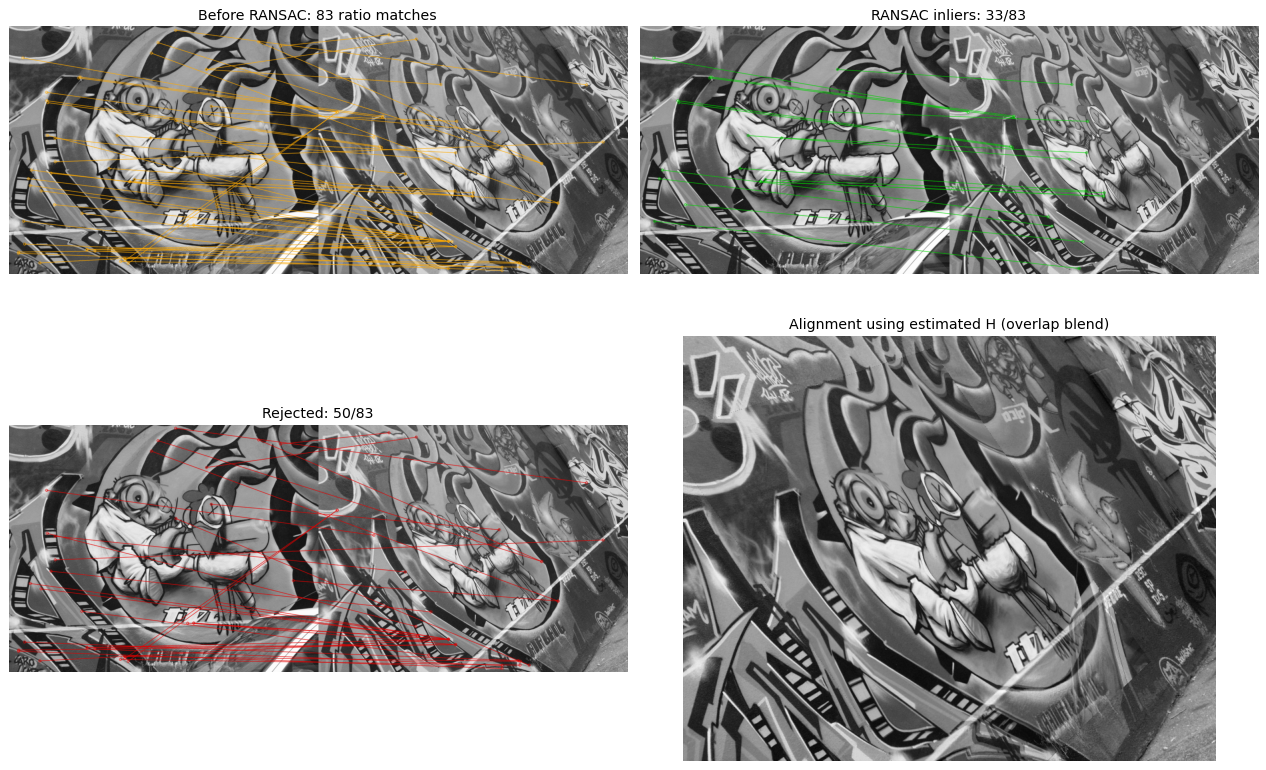

In [6]:
m,aux=evaluate('graf',4,'SIFT',.75)
a,b,k1,k2,good,H,mask,gt=aux
shown=sorted(range(len(good)),key=lambda i:good[i].distance)[:50]
def match_picture(indices,color):
    return cv2.cvtColor(cv2.drawMatches(a,k1,b,k2,[good[i] for i in indices],None,matchColor=color,flags=2),cv2.COLOR_BGR2RGB)
fig,axes=plt.subplots(2,2,figsize=(15,10))
axes[0,0].imshow(match_picture(shown,(0,170,255)));axes[0,0].set_title(f'Before RANSAC: {len(good)} ratio matches')
axes[0,1].imshow(match_picture([i for i in shown if mask[i]],(0,210,0)));axes[0,1].set_title(f'RANSAC inliers: {int(mask.sum())}/{len(good)}')
axes[1,0].imshow(match_picture([i for i in shown if not mask[i]],(0,0,230)));axes[1,0].set_title(f'Rejected: {int((~mask).sum())}/{len(good)}')
if H is not None:
    warped=cv2.warpPerspective(a,H,(b.shape[1],b.shape[0]))
    support=cv2.warpPerspective(np.ones_like(a),H,(b.shape[1],b.shape[0]),flags=cv2.INTER_NEAREST)>0
    blend=b.copy();blend[support]=cv2.addWeighted(warped,.5,b,.5,0)[support]
    axes[1,1].imshow(blend,cmap='gray');axes[1,1].set_title('Alignment using estimated H (overlap blend)')
else:
    axes[1,1].imshow(b,cmap='gray');axes[1,1].set_title('Homography not found')
for ax in axes.ravel():ax.axis('off')
fig.tight_layout();plt.show()
p=np.array([k1[m.queryIdx].pt for m in good],dtype=float).reshape(-1,2)
q=np.array([k2[m.trainIdx].pt for m in good],dtype=float).reshape(-1,2)
e=transfer_errors(p,q,gt)
print('Independent GT precision: all=',float(np.mean(e<=3)) if len(e) else None,
      'RANSAC inliers=',float(np.mean(e[mask]<=3)) if mask.any() else None)


## 4. Настройка и отложенные сцены / Tuning and held-out scenes
RU: выбираем по среднему precision@3px на четырёх validation-парах. Нулевые соответствия дают precision=0; всегда выводим число matches, чтобы один удачный match не выглядел убедительно. При равенстве — лексикографически минимальный ID. Фиксируем выбор до открытия test. После test параметры не меняем.
EN: select by mean precision@3px over four validation pairs. Zero matches yield zero precision. Always report match counts so a single correct match does not look persuasive. Break ties by lexicographic configuration ID. Freeze before opening test. Do not retune after test.

In [7]:
records=[]
for seq in ['graf','leuven']:
    for method in ['SIFT','ORB']:
        for ratio in [.6,.75,.9]:
            for index in [2,4]:
                r,_=evaluate(seq,index,method,ratio)
                r.update(split='validation',config=f'{method}:{ratio}');records.append(r)
selected=choose_config(records)
Path('frozen_config.json').write_text(json.dumps({'selected':selected}))
print('Frozen:',selected)

Frozen: SIFT:0.6


### Validation: фотографии и выбранная конфигурация / Photos and selected configuration
RU: графики показывают выбранные по validation настройки. Числа относятся ко всем соответствиям, линии — к максимум 30 с наименьшим расстоянием дескрипторов.
EN: plots use validation-selected settings. Metrics use all matches; lines show at most 30 matches with the smallest descriptor distance.

In [8]:
# Real Oxford photographs; no synthetic points. / Реальные фото Oxford.
def show_matching_scene(sequence, indices, method, ratio, split):
    fig,axes=plt.subplots(len(indices),3,figsize=(15,3.6*len(indices)),squeeze=False)
    for row,index in enumerate(indices):
        metric,aux=evaluate(sequence,index,method,ratio)
        a,b,k1,k2,good,H,mask,gt=aux
        for ax,img,title in [(axes[row,0],a,f'{sequence}: image 1'),(axes[row,1],b,f'{sequence}: image {index}')]:
            ax.imshow(img,cmap='gray');ax.set_title(title);ax.axis('off')
        chosen=sorted(good,key=lambda m:m.distance)[:30]
        preview=cv2.drawMatches(a,k1,b,k2,chosen,None,matchColor=(0,200,255),singlePointColor=None,flags=2)
        axes[row,2].imshow(cv2.cvtColor(preview,cv2.COLOR_BGR2RGB));axes[row,2].axis('off')
        axes[row,2].set_title(f"matches={metric['matches']}, inliers={metric['inliers']}\nGT precision@3px={metric['precision']:.3f}")
    fig.suptitle(f'{split}: {sequence} | {method}, ratio={ratio} | at most 30 matches shown')
    fig.tight_layout();plt.show()


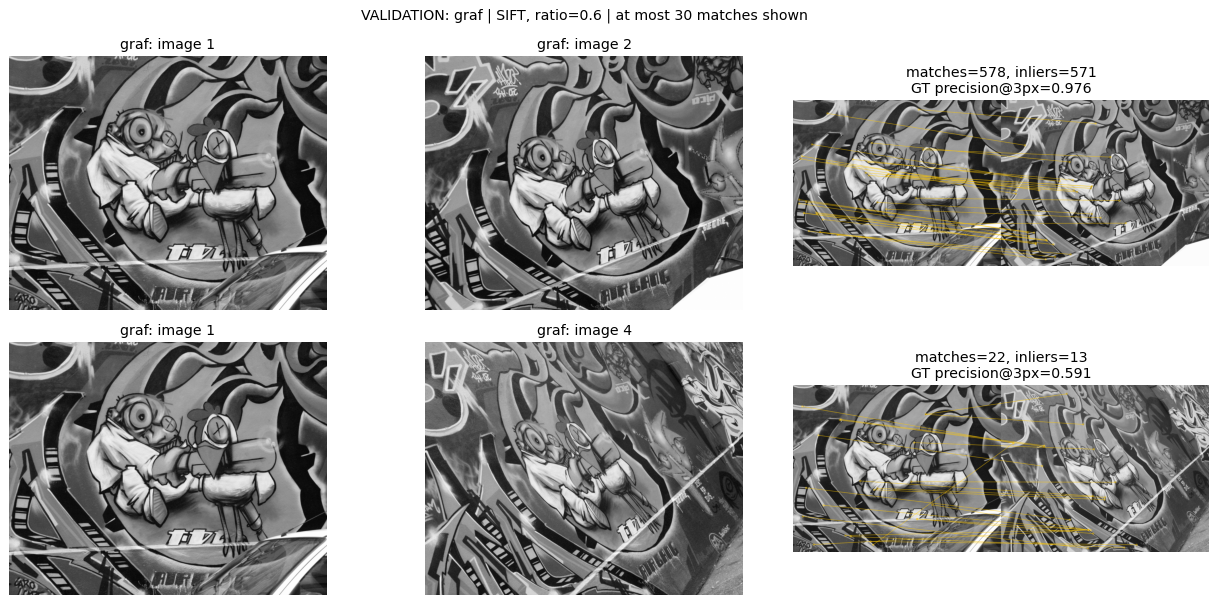

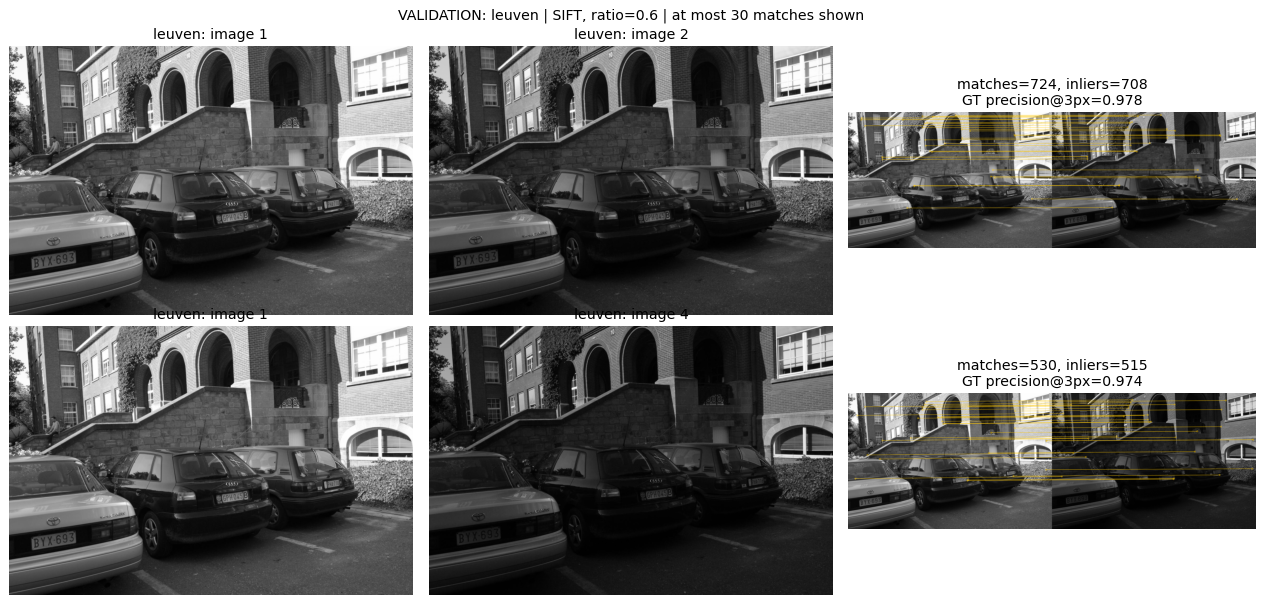

In [9]:
method,ratio=selected.split(':')
for seq in ['graf','leuven']:
    show_matching_scene(seq,[2,4],method,float(ratio),'VALIDATION')


In [10]:
selected=json.loads(Path('frozen_config.json').read_text())['selected']
method,ratio=selected.split(':')
for seq in ['wall','bikes']:
    for index in [2,4,6]:
        r,_=evaluate(seq,index,method,float(ratio));r.update(split='test',config=selected);records.append(r);print(r)
Path('matching_results.json').write_text(json.dumps(records,indent=2))

{'sequence': 'wall', 'pair': '1-2', 'method': 'SIFT', 'ratio': 0.6, 'matches': 677, 'inliers': 677, 'precision': 1.0, 'gt_median_px': 0.992959416368124, 'homography_found': True, 'split': 'test', 'config': 'SIFT:0.6'}
{'sequence': 'wall', 'pair': '1-4', 'method': 'SIFT', 'ratio': 0.6, 'matches': 126, 'inliers': 124, 'precision': 0.9365079365079365, 'gt_median_px': 1.0846217677613526, 'homography_found': True, 'split': 'test', 'config': 'SIFT:0.6'}
{'sequence': 'wall', 'pair': '1-6', 'method': 'SIFT', 'ratio': 0.6, 'matches': 0, 'inliers': 0, 'precision': 0.0, 'gt_median_px': None, 'homography_found': False, 'split': 'test', 'config': 'SIFT:0.6'}
{'sequence': 'bikes', 'pair': '1-2', 'method': 'SIFT', 'ratio': 0.6, 'matches': 387, 'inliers': 371, 'precision': 0.958656330749354, 'gt_median_px': 0.36037524669504895, 'homography_found': True, 'split': 'test', 'config': 'SIFT:0.6'}
{'sequence': 'bikes', 'pair': '1-4', 'method': 'SIFT', 'ratio': 0.6, 'matches': 180, 'inliers': 169, 'precision

### Held-out: фотографии после фиксации / Photos after freezing
RU: открываем wall и bikes только после фиксации. Нулевые matches показываются как две фотографии без линий — это отказ, а не идеальное совпадение. После просмотра параметры не меняем.
EN: inspect wall and bikes only after freezing. Zero matches appear as two photographs without lines: this is failure, not perfect matching. Do not retune after inspection.

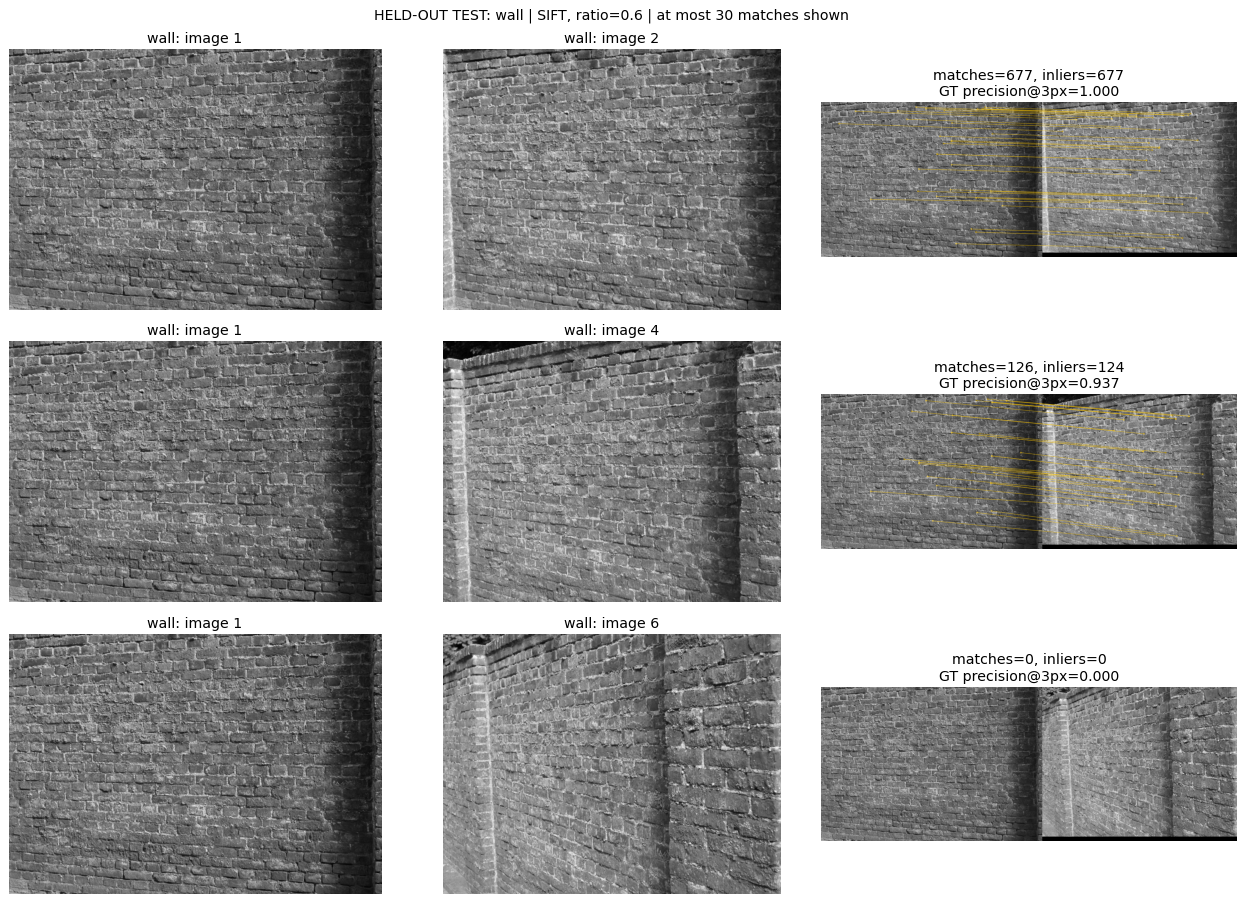

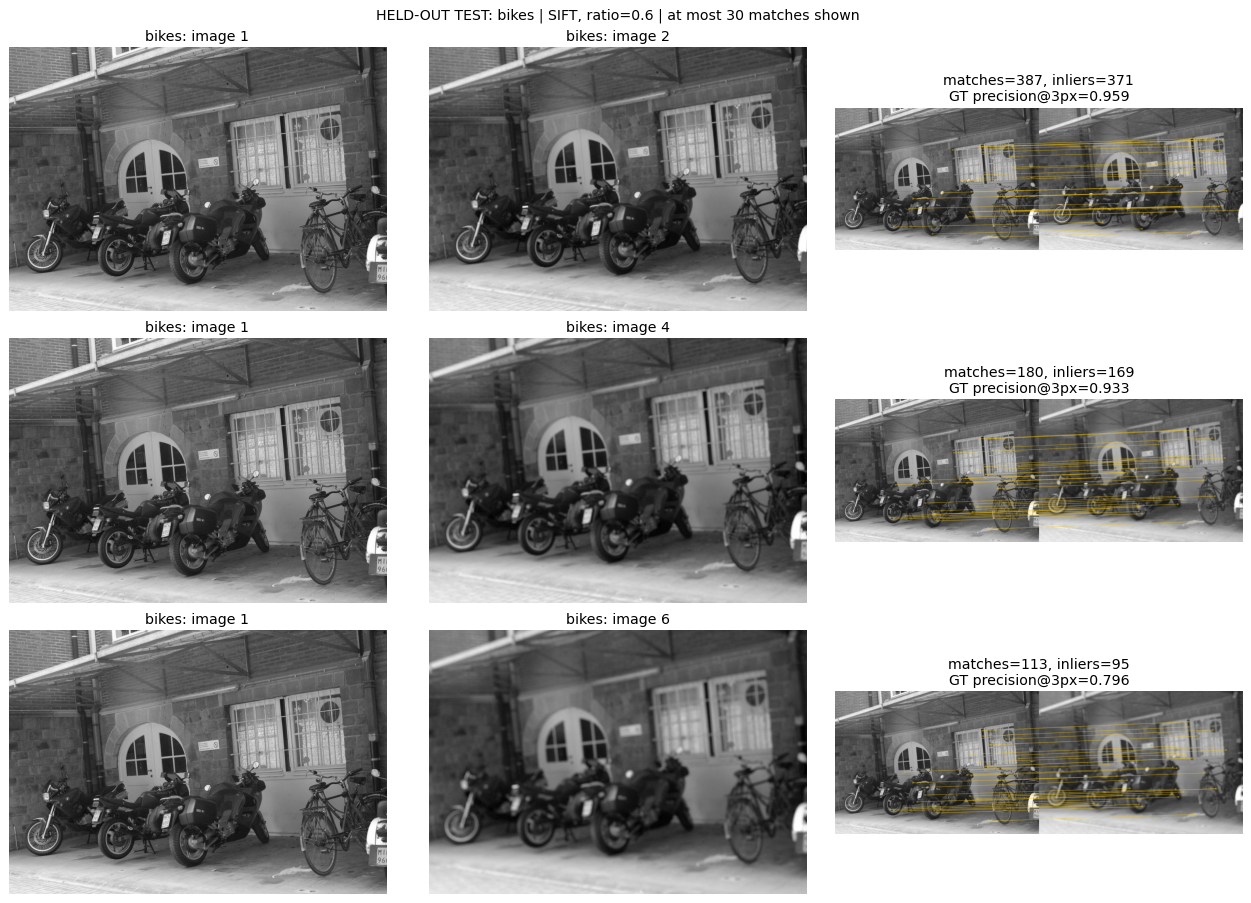

In [11]:
for seq in ['wall','bikes']:
    show_matching_scene(seq,[2,4,6],method,float(ratio),'HELD-OUT TEST')


## Четыре задания на занятии / Four in-class tasks
1. **Дескрипторы / Descriptors (10 мин / min).** На `graf` 1–2 сравните SIFT и ORB: размерность, dtype, норму и число соответствий. Объясните выбор нормы. / Compare dimensions, dtype, distance norm and match counts on `graf` 1–2. Explain each norm.
2. **Ratio test (15 мин / min).** На validation-парах сравните 0.6, 0.75 и 0.9. Покажите количество и precision@3px. Объясните компромисс, не выбирая по test. / Compare the three thresholds on validation pairs. Report counts and precision. Explain the trade-off without tuning on test.
3. **RANSAC (15 мин / min).** На `graf` 1–4 сравните пороги 1, 3 и 6 px. Выведите маску inliers и независимую ошибку относительно H_gt. / Compare thresholds of 1, 3 and 6 px on `graf` 1–4. Show inliers and independent ground-truth error.
4. **Отложенная оценка / Held-out evaluation (15 мин / min).** Зафиксируйте конфигурацию, оцените `wall` и `bikes`, объясните один провал и ограничение вывода по двум сценам. / Freeze configuration, evaluate `wall` and `bikes`, explain a failure and the limits of inference from two scenes.

Сдайте ноутбук с выводами и `matching_results.json`. Отметку практики ставит преподаватель. / Submit the executed notebook with explanations and results JSON. The instructor records practice completion.

## Переиспользовано и обновлено / Reuse and updates
RU: из авторского курса сохранены SIFT, ORB, matching и выравнивание. Обновление 2026: реальные серии Oxford, проверка загрузки, независимая геометрическая метрика, разделение сцен и явный отказ при нехватке matches. LightGlue рассматриваем в лекции как факультативное продолжение.
EN: the instructor's SIFT, ORB, matching and alignment topics are retained. The 2026 update adds real Oxford sequences, verified downloads, independent geometry metrics, scene separation and explicit failure handling. LightGlue is an optional lecture extension.


## Решение 1. Дескрипторы / Solution 1. Descriptors
RU: SIFT — 128 вещественных компонент, расстояние L2; ORB — 32 байта (256 бит), Hamming считает различающиеся биты при WTA_K=2. Расстояние L2 между значениями байтов ORB не соответствует сравнению бинарных тестов. Больше matches не обязательно означает более точные matches.
EN: SIFT has 128 floating-point components and uses L2. ORB has 32 bytes (256 bits); Hamming counts different bits for WTA_K=2. L2 on byte values does not compare the underlying binary tests. More matches need not mean better matches.

In [12]:
a,b,_=pair('graf',2)
for method in ['SIFT','ORB']:
    k1,d1=features(a,method);k2,d2=features(b,method)
    matches=ratio_filter(neighbors(d1,d2,method),.75)
    print(method, {'shape': d1.shape, 'dtype': str(d1.dtype),
          'norm': 'L2' if method=='SIFT' else 'Hamming', 'matches':len(matches)})


SIFT {'shape': (1500, 128), 'dtype': 'float32', 'norm': 'L2', 'matches': 673}
ORB {'shape': (1500, 32), 'dtype': 'uint8', 'norm': 'Hamming', 'matches': 565}


## Решение 2. Ratio test / Solution 2. Ratio test
RU: меньший порог требует большего отрыва первого соседа от второго, обычно удаляя неоднозначные соответствия ценой покрытия. Рост precision не гарантирован на каждой паре; смотрим реальные результаты и число matches. Выбор — по macro precision на validation, не по test.
EN: a lower threshold requires a larger gap between the first and second neighbours, usually removing ambiguous matches at the cost of coverage. Precision need not improve on every pair; inspect actual results and match counts. Select using validation macro precision, never test.

In [13]:
validation=[r for r in records if r['split']=='validation']
for r in validation:
    print(r['config'],r['sequence'],r['pair'], 'matches=',r['matches'], 'precision=',round(r['precision'],4))
for config in sorted({r['config'] for r in validation}):
    rows=[r for r in validation if r['config']==config]
    print('macro',config,'precision=',round(float(np.mean([r['precision'] for r in rows])),4),
          'mean matches=',round(float(np.mean([r['matches'] for r in rows])),1))
assert choose_config(validation)==selected
print('Validation-selected / Выбрано по validation:',selected)


SIFT:0.6 graf 1-2 matches= 578 precision= 0.9758
SIFT:0.6 graf 1-4 matches= 22 precision= 0.5909
SIFT:0.75 graf 1-2 matches= 673 precision= 0.9138
SIFT:0.75 graf 1-4 matches= 83 precision= 0.4096
SIFT:0.9 graf 1-2 matches= 868 precision= 0.7477
SIFT:0.9 graf 1-4 matches= 408 precision= 0.2034
ORB:0.6 graf 1-2 matches= 311 precision= 0.9582
ORB:0.6 graf 1-4 matches= 1 precision= 0.0
ORB:0.75 graf 1-2 matches= 565 precision= 0.9363
ORB:0.75 graf 1-4 matches= 36 precision= 0.3611
ORB:0.9 graf 1-2 matches= 956 precision= 0.8421
ORB:0.9 graf 1-4 matches= 353 precision= 0.238
SIFT:0.6 leuven 1-2 matches= 724 precision= 0.9779
SIFT:0.6 leuven 1-4 matches= 530 precision= 0.9736
SIFT:0.75 leuven 1-2 matches= 801 precision= 0.9438
SIFT:0.75 leuven 1-4 matches= 638 precision= 0.9185
SIFT:0.9 leuven 1-2 matches= 968 precision= 0.8264
SIFT:0.9 leuven 1-4 matches= 838 precision= 0.7578
ORB:0.6 leuven 1-2 matches= 497 precision= 0.9718
ORB:0.6 leuven 1-4 matches= 273 precision= 0.9524
ORB:0.75 leuven

## Решение 3. RANSAC / Solution 3. RANSAC
RU: увеличивая порог, мы разрешаем больший остаток относительно найденной модели. Маски разных запусков не обязаны быть вложенными. Сравниваем независимую ошибку H_gt на отобранных inliers: высокая доля inliers ещё не доказывает правильность модели.
EN: increasing the threshold permits larger residuals to the fitted model. Masks from separate runs need not be nested. Compare independent H_gt errors on selected inliers: a high inlier fraction alone does not prove a correct model.

In [14]:
a,b,gt=pair('graf',4)
k1,d1=features(a,'SIFT');k2,d2=features(b,'SIFT')
good=ratio_filter(neighbors(d1,d2,'SIFT'),.75)
p=np.array([k1[m.queryIdx].pt for m in good],dtype=float).reshape(-1,2)
q=np.array([k2[m.trainIdx].pt for m in good],dtype=float).reshape(-1,2)
gt_error=transfer_errors(p,q,gt)
for threshold in [1.,3.,6.]:
    H,mask=estimate_homography(k1,k2,good,threshold)
    print('threshold=',threshold,'inliers=',int(mask.sum()),'/',len(good))
    print('mask=',mask.astype(int).tolist())
    print('GT median on inliers=',float(np.median(gt_error[mask])) if mask.any() else None,
          'GT precision on inliers=',float(np.mean(gt_error[mask]<=3)) if mask.any() else None)
    if H is not None:
        print('Estimated-model median=',float(np.median(transfer_errors(p[mask],q[mask],H))) if mask.any() else None)


threshold= 1.0 inliers= 22 / 83
mask= [0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
GT median on inliers= 0.8628391897287904 GT precision on inliers= 1.0
Estimated-model median= 0.5638183437001849
threshold= 3.0 inliers= 33 / 83
mask= [0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0]
GT median on inliers= 0.9877689553712674 GT precision on inliers= 0.9696969696969697
Estimated-model median= 0.9976619709564947
threshold= 6.0 inliers= 40 / 83
mask= [0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 

## Решение 4. Отложенная оценка / Solution 4. Held-out evaluation
RU: конфигурация уже зафиксирована в frozen_config.json до оценки test. Ниже выводим все пары и визуализируем пару с минимальным precision для анализа ошибок, а не для перенастройки. Для bikes возможная причина — размытие, для wall — изменение ракурса и повторяющаяся текстура. Это гипотезы: сопоставьте их с изображением. «Худшая» пара не обязательно означает полный отказ алгоритма. По двум сценам нельзя обещать обобщение на все фотографии.
EN: frozen_config.json was written before test evaluation. Report all pairs and visualize the lowest-precision pair for error analysis, not retuning. Possible causes are blur for bikes and viewpoint change or repeated texture for wall; check these hypotheses against the images. The worst pair is not necessarily a complete failure. Two scenes cannot establish generalization to all photographs.

In [15]:
test=[r for r in records if r['split']=='test']
assert len(test)==6 and all(r['config']==selected for r in test)
for r in test:print(r)
print('Test macro precision:',float(np.mean([r['precision'] for r in test])))
worst=min(test,key=lambda r:r['precision'])
print('Inspect / Разбираем:',worst)
metric,aux=evaluate(worst['sequence'],int(worst['pair'].split('-')[1]),worst['method'],worst['ratio'])
a,b,k1,k2,good,H,mask,gt=aux
p=np.array([k1[m.queryIdx].pt for m in good],dtype=float).reshape(-1,2)
q=np.array([k2[m.trainIdx].pt for m in good],dtype=float).reshape(-1,2)
error=transfer_errors(p,q,gt)
wrong=[m for m,e in zip(good,error) if e>3]
print('Wrong matches / Ошибочные:',len(wrong),'/',len(good),'homography found:',H is not None)
view=cv2.drawMatches(a,k1,b,k2,wrong[:40],None,flags=2)
plt.figure(figsize=(14,6));plt.imshow(cv2.cvtColor(view,cv2.COLOR_BGR2RGB));plt.axis('off');plt.show()
# Preserve the validation-selected configuration. / Выбор не меняем.
assert json.loads(Path('frozen_config.json').read_text())['selected']==selected


{'sequence': 'wall', 'pair': '1-2', 'method': 'SIFT', 'ratio': 0.6, 'matches': 677, 'inliers': 677, 'precision': 1.0, 'gt_median_px': 0.992959416368124, 'homography_found': True, 'split': 'test', 'config': 'SIFT:0.6'}
{'sequence': 'wall', 'pair': '1-4', 'method': 'SIFT', 'ratio': 0.6, 'matches': 126, 'inliers': 124, 'precision': 0.9365079365079365, 'gt_median_px': 1.0846217677613526, 'homography_found': True, 'split': 'test', 'config': 'SIFT:0.6'}
{'sequence': 'wall', 'pair': '1-6', 'method': 'SIFT', 'ratio': 0.6, 'matches': 0, 'inliers': 0, 'precision': 0.0, 'gt_median_px': None, 'homography_found': False, 'split': 'test', 'config': 'SIFT:0.6'}
{'sequence': 'bikes', 'pair': '1-2', 'method': 'SIFT', 'ratio': 0.6, 'matches': 387, 'inliers': 371, 'precision': 0.958656330749354, 'gt_median_px': 0.36037524669504895, 'homography_found': True, 'split': 'test', 'config': 'SIFT:0.6'}
{'sequence': 'bikes', 'pair': '1-4', 'method': 'SIFT', 'ratio': 0.6, 'matches': 180, 'inliers': 169, 'precision

## Выводы проверенного запуска / Verified-run conclusions

**RU.** CPU, OpenCV 4.12: validation выбрала `SIFT:0.6` (macro precision ≈ 0.8795). Test macro precision ≈ 0.7708. На `wall 1–6` осталось 0 matches: недостаточно даже для минимальных четырёх соответствий, H отсутствует. Ноль ошибочных matches при нуле всех matches не означает идеальную работу. Причину потери соответствий проверяем по ракурсу и видимости текстуры; по одной метрике причинность установить нельзя. Не ослабляем ratio по результату test. На `graf 1–4` увеличение RANSAC-порога с 3 до 6 px повысило число inliers с 33 до 40, но снизило их независимый precision с ≈0.970 до 0.850. Больше inliers — не всегда лучше.

**EN.** On CPU with OpenCV 4.12, validation selected `SIFT:0.6` (macro precision ≈0.8795). Test macro precision was ≈0.7708. `wall 1–6` retained zero matches, fewer than the minimum four needed for H. Zero incorrect matches out of zero total does not mean perfect performance. Inspect viewpoint and visible texture to investigate lost matches; metrics alone cannot establish causation. Do not loosen the ratio threshold after seeing test results. On `graf 1–4`, increasing RANSAC's threshold from 3 to 6 px raised inliers from 33 to 40 but lowered their independent precision from ≈0.970 to 0.850. More inliers is not always better.

Числа могут немного зависеть от версии библиотек. Графики строятся при запуске ячеек. / Values may vary slightly with library versions. Run the cells to render plots.
